In [2]:
import supermarq as sm
import qiskit
import qiskit_superstaq as qss
from qiskit import Aer, execute, QuantumCircuit


from qiskit.converters import circuit_to_dag
from qiskit.tools.visualization import dag_drawer
# dag = circuit_to_dag(circ)
# dag_drawer(dag)

from pprint import pprint
import sys
import numpy
numpy.set_printoptions(threshold=sys.maxsize)

In [3]:
import termcolor
def matrix_print(nparray, size=8):
    for x in nparray:
        for y in x:
            r = '{:+02.1f}'.format(y.real)
            i = '{:+02.1f}'.format(y.imag)
            if i not in ['+0.0', '-0.0'] or r not in ['+0.0', '-0.0']:
                r = termcolor.colored(r, 'red')
                i = termcolor.colored(i, 'red')
            print("(", r, ",", i, ")",sep="", end="  ")
        print(end="\n\n")
def remove_gates(circ, to_remove=['measure', 'reset', 'h']):
    marked = []
    for ins in circ.data:
        if ins[0].name in to_remove:
            marked.append(ins)
    marked = marked[::-1]
    for each in marked:
        circ.data.remove(each)
    return circ

In [25]:
from qiskit.extensions.unitary import UnitaryGate
from numpy import savez
def write_gates_to_file(circ, n, directory):
    ins_num = 1
    for ins in circ.data:
        print(ins)
        qc = QuantumCircuit(n)
        qc.data = [ins]
        unitary_backend = Aer.get_backend('unitary_simulator')
        job = execute(qc, unitary_backend, shots=10)
        mat = job.result().get_unitary(qc, n).data
        matrix_print01(mat)
        # gate = UnitaryGate(ins.operation)
        # mat = gate.to_matrix()
        # matrix_print(mat)
#         savez(directory + '/gate_' + str(ins_num) + '.npz', mat)
        ins_num += 1

In [5]:
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)
    # Apply transformation |s> -> |00..0> (H-gates)
    for qubit in range(nqubits):
        qc.h(qubit)
    # Apply transformation |00..0> -> |11..1> (X-gates)
    for qubit in range(nqubits):
        qc.x(qubit)
    # Do multi-controlled-Z gate
    qc.h(nqubits-1)
    qc.mct(list(range(nqubits-1)), nqubits-1)  # multi-controlled-toffoli
    qc.h(nqubits-1)
    # Apply transformation |11..1> -> |00..0>
    for qubit in range(nqubits):
        qc.x(qubit)
    # Apply transformation |00..0> -> |s>
    for qubit in range(nqubits):
        qc.h(qubit)
    # We will return the diffuser as a gate
    U_s = qc.to_gate()
    U_s.name = "U$_s$"
    return U_s

In [6]:
def initialize_s(qc, qubits):
    """Apply a H-gate to 'qubits' in qc"""
    for q in qubits:
        qc.h(q)
    return qc

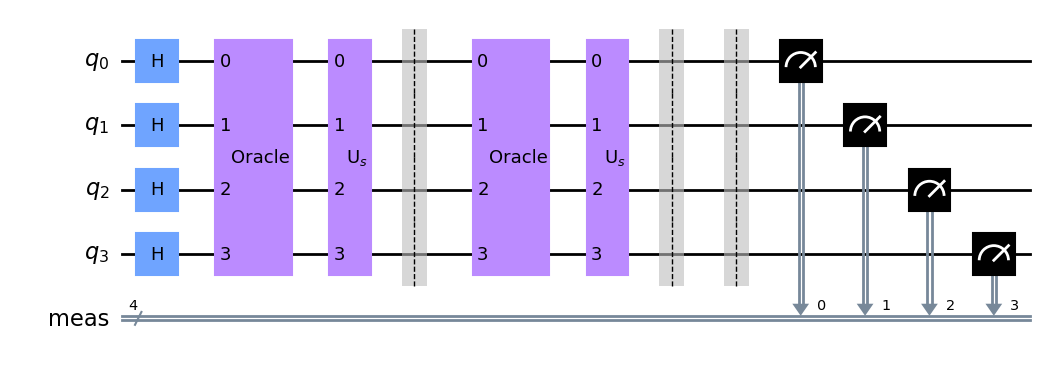

In [21]:
from qiskit_textbook.problems import grover_problem_oracle
## Example Usage
n = 4
iterations = 2
oracle_tb = grover_problem_oracle(n, variant=3)
# hw oracle
myqc = QuantumCircuit(4, name='Oracle')
myqc.x(1)
myqc.z(range(2))
myqc.x(1)
oracle = myqc.to_gate()

grover_circuit = QuantumCircuit(n)
grover_circuit = initialize_s(grover_circuit, list(range(n)))

for i in range(iterations):
    grover_circuit.append(oracle, list(range(n)))
    grover_circuit.append(diffuser(n), list(range(n)))
    grover_circuit.barrier()

grover_circuit.measure_all()
grover_circuit.draw(output="mpl")

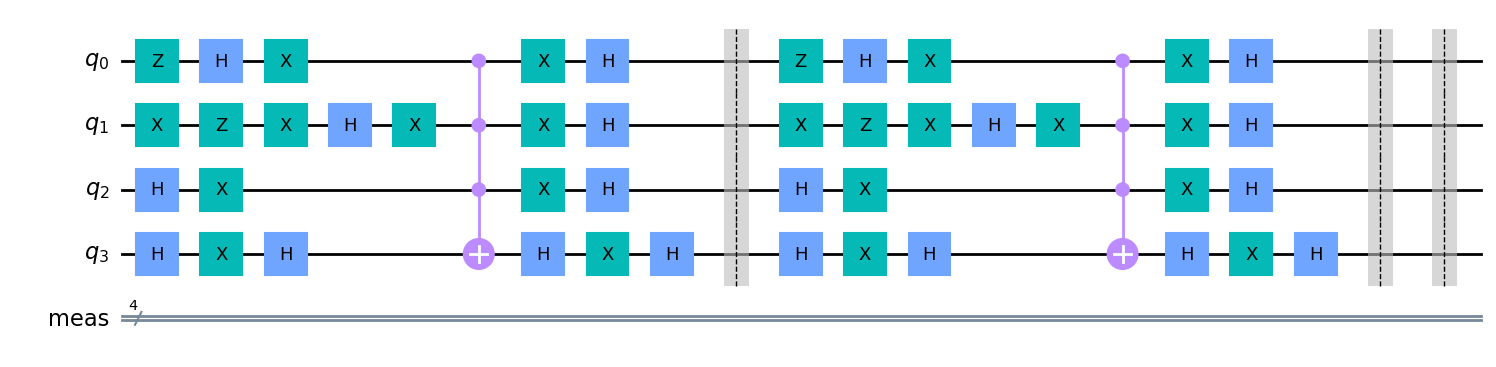

In [29]:
grover_new = remove_gates(grover_circuit)
basic_gate_grover = grover_new.decompose()
basic_gate_grover.draw(output="mpl")

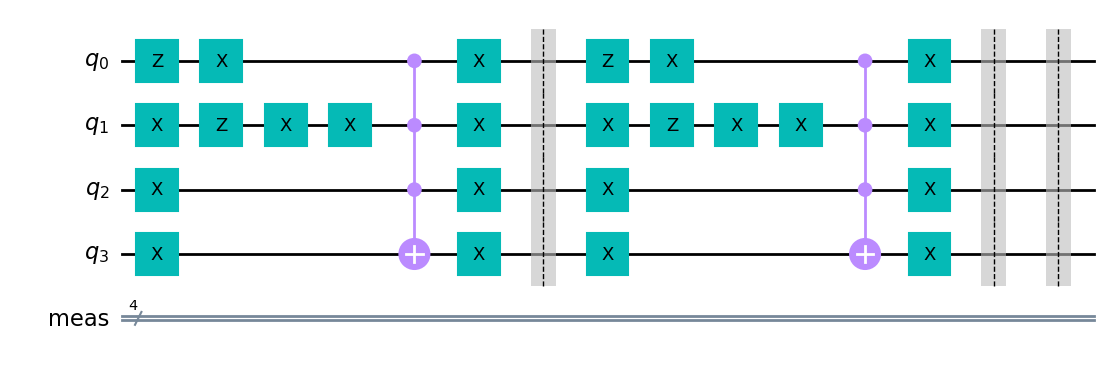

In [30]:
basic_gate_grover_new = remove_gates(basic_gate_grover)
basic_gate_grover_new.draw(output="mpl")

In [23]:
def matrix_print01(nparray):
    for x in nparray:
        for y in x:
            a = int(y.real != 0.0 or y.imag != 0.0)
#             print(y.real, y.imag, a)
            if a != 0:
                print(termcolor.colored("*", 'red') ,end=" ", sep="")
            else:
                print(a, end=" ", sep="")
        print()

In [31]:
write_gates_to_file(basic_gate_grover_new, n, "../../data/other/grover3/" + str(n))

(Instruction(name='z', num_qubits=1, num_clbits=0, params=[]), [Qubit(QuantumRegister(4, 'q'), 0)], [])
* 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 
(Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), [Qubit(QuantumRegister(4, 'q'), 0)], [])
0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
* 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 


In [13]:
unitary_backend = Aer.get_backend('unitary_simulator')
job = execute(grover_new, unitary_backend, shots=1024)
result = job.result()
d = result.get_unitary(grover_new, 3).data

In [14]:
matrix_print01(d)

* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
* * * * * * * * * * * * * * * * 
